# 🏛️ HỌC VIỆN NGÂN HÀNG (BANKING ACADEMY)
### KHOA HỆ THỐNG THÔNG TIN QUẢN LÝ / NGÂN HÀNG
---
# 📊 BÀI TẬP GIỮA KỲ: XỬ LÝ DỮ LIỆU & KHAI PHÁ DỮ LIỆU
## ĐỀ TÀI: PHÂN TÍCH HÀNH VI, PHÂN CỤM & DỰ BÁO NGUY CƠ RỜI BỎ CỦA KHÁCH HÀNG THẺ TÍN DỤNG
### *(BANK CUSTOMER CHURN ANALYSIS & PREDICTIVE MODELING)*

* **Học phần:** Phân tích Dữ liệu trong Kinh doanh (*Business Analytics*)
* **Tập dữ liệu:** `BankChurners.csv` (10,127 quan sát, 23 thuộc tính ban đầu)
* **Sinh viên thực hiện:** Đỗ Văn Đạt
* **Thời gian thực hiện:** Năm học 2025 - 2026

---
## 📑 MỤC LỤC NỘI DUNG:
1. **Khởi tạo môi trường & Đọc dữ liệu**
2. **Tiền xử lý & Làm sạch dữ liệu (Data Preprocessing & Cleaning)**
3. **Kỹ thuật tạo biến (Feature Engineering)**
4. **Phân tích Khám phá Dữ liệu Chuyên sâu (Exploratory Data Analysis - EDA)**
5. **Khai phá Dữ liệu: Phân cụm Khách hàng Hành vi (K-Means Clustering & PCA)**
6. **Khai phá Dữ liệu: Mô hình hóa Dự báo Rời bỏ (Supervised Classification)**
7. **Đánh giá Hiệu năng & So sánh Đường cong ROC-AUC**
8. **Giải thích Mô hình & Tầm quan trọng Đặc trưng (Feature Importance)**
9. **Tối ưu hóa Ngưỡng Xác suất & Bài toán Kinh tế Giữ chân (Cost-Benefit Analysis)**
10. **Tổng kết & Khung Khuyến nghị Quản trị Giữ chân Khách hàng**


## 🛠️ 1. Khởi tạo môi trường & Cấu hình trực quan

In [1]:
import os
import sys
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import (
    silhouette_score, accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, roc_curve, confusion_matrix, classification_report
)
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

# Cấu hình thẩm mỹ đồ họa
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['font.size'] = 11
plt.rcParams['figure.titlesize'] = 15
plt.rcParams['figure.titleweight'] = 'bold'
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['axes.titleweight'] = 'bold'

COLOR_EXISTING = '#1E3A8A'  # Navy
COLOR_ATTRITED = '#EF4444'  # Red
PALETTE = {'Existing Customer': COLOR_EXISTING, 'Attrited Customer': COLOR_ATTRITED}

print("✅ Đã import đầy đủ các thư viện phân tích & máy học!")


✅ Đã import đầy đủ các thư viện phân tích & máy học!


## 📌 2. Khám phá Cấu trúc Dữ liệu & Đọc Dữ liệu Thô

In [2]:
df_raw = pd.read_csv('BankChurners.csv')
print(f"Kích thước tập dữ liệu: {df_raw.shape[0]:,} dòng, {df_raw.shape[1]} cột")
df_raw.head()


Kích thước tập dữ liệu: 10,127 dòng, 23 cột


,CLIENTNUM,Attrition_Flag,Customer_Age,Gender,Dependent_count,Education_Level,Marital_Status,Income_Category,Card_Category,Months_on_book,...,Credit_Limit,Total_Revolving_Bal,Avg_Open_To_Buy,Total_Amt_Chng_Q4_Q1,Total_Trans_Amt,Total_Trans_Ct,Total_Ct_Chng_Q4_Q1,Avg_Utilization_Ratio,Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contacts_Count_12_mon_Dependent_count_Education_Level_Months_Inactive_12_mon_1,Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contacts_Count_12_mon_Dependent_count_Education_Level_Months_Inactive_12_mon_2
0,768805383,Existing Customer,45,M,3,High School,Married,$60K - $80K,Blue,39,...,12691.0,777.0,11914.0,1.335,1144,42,1.625,0.061,0.000093,0.99991
1,818770008,Existing Customer,49,F,5,Graduate,Single,Less than $40K,Blue,44,...,8256.0,864.0,7392.0,1.541,1291,33,3.714,0.105,0.000057,0.99994
2,713982108,Existing Customer,51,M,3,Graduate,Married,$80K - $120K,Blue,36,...,3418.0,NaN,3418.0,2.594,1887,20,2.333,0.000,0.000021,0.99998
3,769911858,Existing Customer,40,F,4,High School,Unknown,Less than $40K,Blue,34,...,3313.0,2517.0,796.0,1.405,1171,20,2.333,0.760,0.000134,0.99987
4,709106358,Existing Customer,40,M,3,Uneducated,Married,$60K - $80K,Blue,21,...,4716.0,0.0,4716.0,2.175,816,28,2.500,0.000,0.000022,0.99998


## 🧹 3. Tiền xử lý & Làm sạch dữ liệu (Data Preprocessing)
1. **Loại bỏ cột nhiễu kỹ thuật:** 2 cột Naive Bayes Classifier ở cuối bảng được tạo sẵn từ thí nghiệm trước, cần loại bỏ để tránh rò rỉ dữ liệu (*Data Leakage*).
2. **Kiểm tra và xử lý giá trị khuyết thiếu (Missing Values):** Đánh giá các ô trống và điền giá trị trung vị (Median) cho các biến số nếu cần.
3. **Phân tích nhóm `'Unknown'`:** Giữ nguyên danh mục `'Unknown'` trong `Education_Level`, `Income_Category`, `Marital_Status` như một phân lớp thông tin độc lập.


In [3]:
# 1. Loại bỏ cột Naive Bayes thừa
cols_to_drop = [c for c in df_raw.columns if c.startswith('Naive_Bayes_Classifier')]
df = df_raw.drop(columns=cols_to_drop).copy()

# 2. Xử lý missing values bằng Median cho biến định lượng
num_cols_list = df.select_dtypes(include=[np.number]).columns.tolist()
for col in num_cols_list:
    if df[col].isnull().sum() > 0:
        df[col] = df[col].fillna(df[col].median())

# 3. Thống kê tỷ lệ 'Unknown' trong các biến phân loại
cat_cols = df.select_dtypes(include=['object']).columns.tolist()
for col in cat_cols:
    unknown_ct = (df[col] == 'Unknown').sum()
    if unknown_ct > 0:
        print(f"Cột '{col}': có {unknown_ct:,} giá trị 'Unknown' ({unknown_ct/len(df):.2%})")
print("✅ Đã hoàn thành kiểm tra và làm sạch missing values!")


Cột 'Education_Level': có 1,519 giá trị 'Unknown' (15.00%)
Cột 'Marital_Status': có 749 giá trị 'Unknown' (7.40%)
Cột 'Income_Category': có 1,112 giá trị 'Unknown' (10.98%)
✅ Đã hoàn thành kiểm tra và làm sạch missing values!


## ⚙️ 4. Kỹ thuật Tạo Đặc trưng Mới (Feature Engineering)
Tạo các chỉ số tài chính và hành vi có ý nghĩa kinh tế cao:
* `Avg_Trans_Value`: Giá trị trung bình của mỗi lần quẹt thẻ ($Total\_Trans\_Amt / Total\_Trans\_Ct$).
* `Age_Group`: Phân khúc lứa tuổi ($<35, 35-44, 45-54, 55-64, 65+$).
* `Revolving_Ratio`: Tỷ lệ dư nợ quay vòng trên tổng hạn mức tín dụng ($Total\_Revolving\_Bal / Credit\_Limit$).
* `Contact_Intensity`: Cường độ liên hệ CSKH trên mỗi tháng hoạt động.
* `Churn_Binary`: Mã hóa nhị phân biến mục tiêu ($1$: Khách hàng rời bỏ, $0$: Khách hàng ở lại).


In [4]:
df['Age_Group'] = pd.cut(
    df['Customer_Age'],
    bins=[0, 35, 45, 55, 65, 100],
    labels=['<35', '35-44', '45-54', '55-64', '65+'],
    right=False
)
df['Avg_Trans_Value'] = df['Total_Trans_Amt'] / df['Total_Trans_Ct']
df['Churn_Binary'] = (df['Attrition_Flag'] == 'Attrited Customer').astype(int)
df['Trans_Per_Month'] = df['Total_Trans_Ct'] / df['Months_on_book']
df['Revolving_Ratio'] = df['Total_Revolving_Bal'] / (df['Credit_Limit'] + 1e-5)
df['Contact_Intensity'] = df['Contacts_Count_12_mon'] / (df['Months_Inactive_12_mon'] + 1)

print("Kích thước sau khi Feature Engineering:", df.shape)
df[['Customer_Age', 'Age_Group', 'Avg_Trans_Value', 'Revolving_Ratio', 'Churn_Binary']].head()


Kích thước sau khi Feature Engineering: (10127, 27)


,Customer_Age,Age_Group,Avg_Trans_Value,Revolving_Ratio,Churn_Binary
0,45,45-54,27.238095,0.061224,0
1,49,45-54,39.121212,0.104651,0
2,51,45-54,94.350000,0.373464,0
3,40,35-44,58.550000,0.759734,0
4,40,35-44,29.142857,0.000000,0


## 📊 5. Phân tích Khám phá Dữ liệu Chuyên sâu (EDA)

### 5.1. Phân bố Biến Mục tiêu (`Attrition_Flag`)

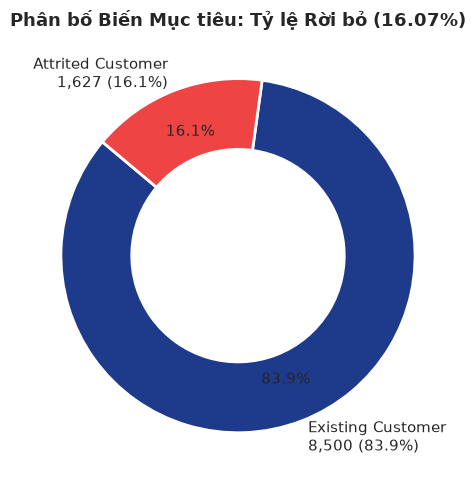

In [5]:
fig, ax = plt.subplots(figsize=(7, 5))
counts = df['Attrition_Flag'].value_counts()
labels = [f"Existing Customer\n{counts['Existing Customer']:,} ({counts['Existing Customer']/len(df):.1%})",
          f"Attrited Customer\n{counts['Attrited Customer']:,} ({counts['Attrited Customer']/len(df):.1%})"]
ax.pie(counts, labels=labels, autopct='%1.1f%%', startangle=140, colors=[COLOR_EXISTING, COLOR_ATTRITED],
       wedgeprops=dict(width=0.4, edgecolor='w', linewidth=2), pctdistance=0.75)
ax.set_title("Phân bố Biến Mục tiêu: Tỷ lệ Rời bỏ (16.07%)")
plt.tight_layout()
plt.show()


### 5.2. Phân tích Nhân khẩu học & Rủi ro Rời bỏ

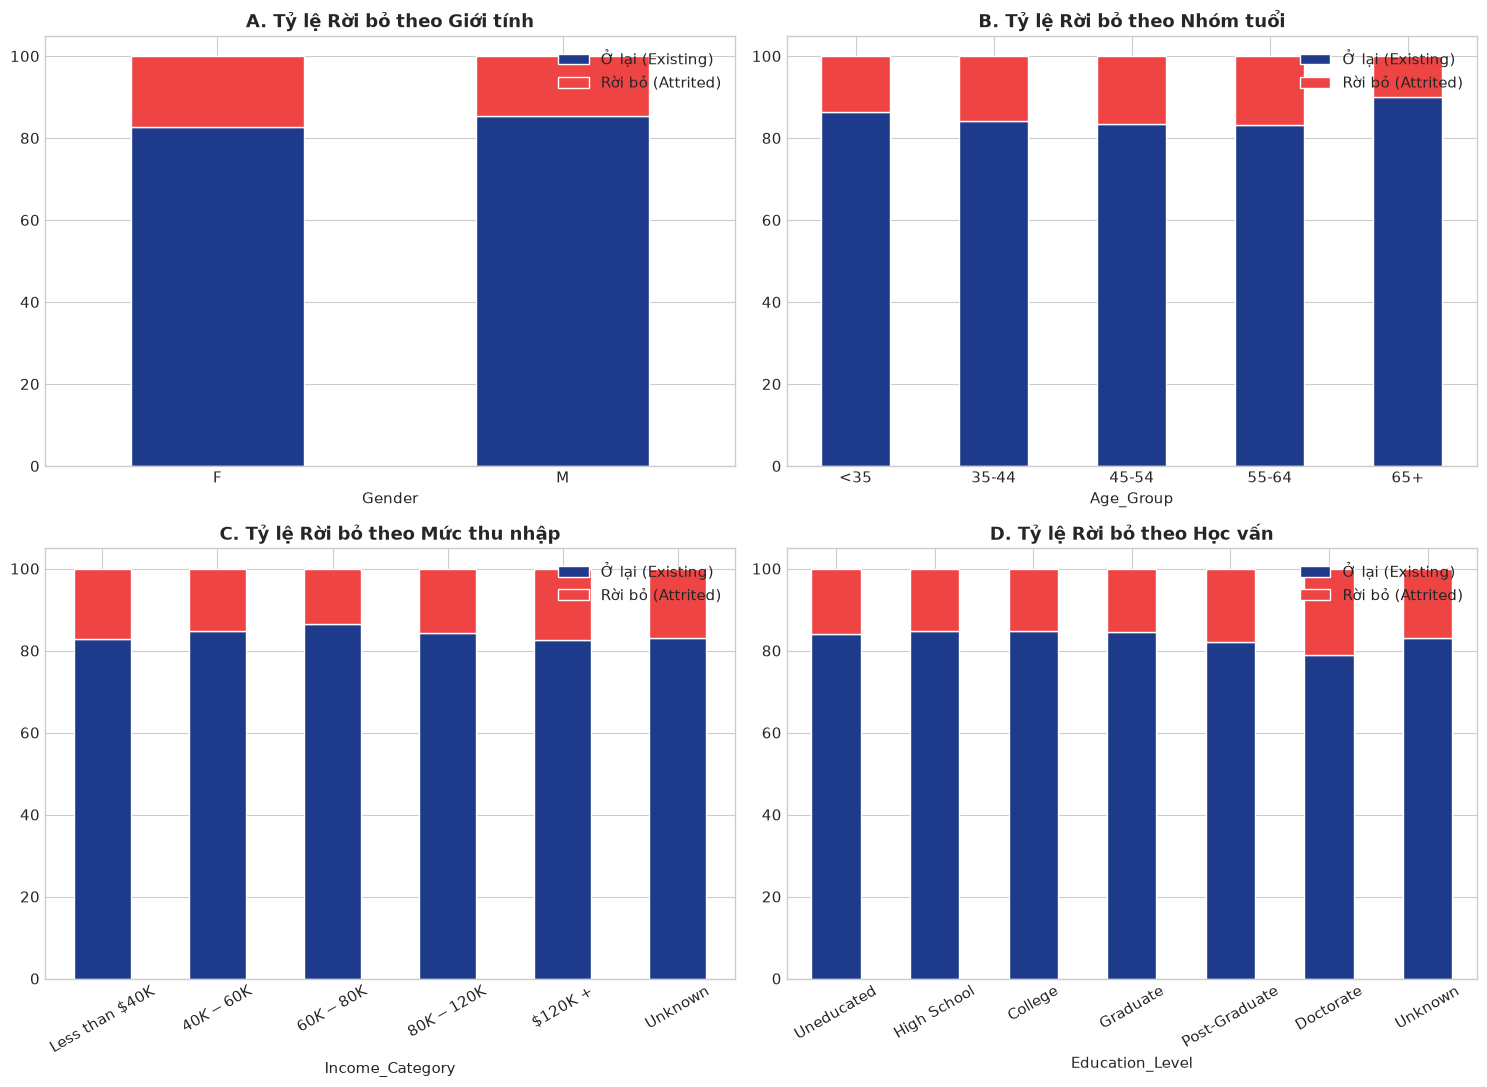

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(15, 11))

# Giới tính
gender_ct = pd.crosstab(df['Gender'], df['Attrition_Flag'], normalize='index') * 100
gender_ct[['Existing Customer', 'Attrited Customer']].plot(
    kind='bar', stacked=True, color=[COLOR_EXISTING, COLOR_ATTRITED], ax=axes[0, 0], edgecolor='white'
)
axes[0, 0].set_title("A. Tỷ lệ Rời bỏ theo Giới tính")
axes[0, 0].tick_params(axis='x', rotation=0)

# Nhóm tuổi
age_ct = pd.crosstab(df['Age_Group'], df['Attrition_Flag'], normalize='index') * 100
age_ct[['Existing Customer', 'Attrited Customer']].plot(
    kind='bar', stacked=True, color=[COLOR_EXISTING, COLOR_ATTRITED], ax=axes[0, 1], edgecolor='white'
)
axes[0, 1].set_title("B. Tỷ lệ Rời bỏ theo Nhóm tuổi")
axes[0, 1].tick_params(axis='x', rotation=0)

# Mức thu nhập
income_order = ['Less than $40K', '$40K - $60K', '$60K - $80K', '$80K - $120K', '$120K +', 'Unknown']
income_ct = pd.crosstab(df['Income_Category'], df['Attrition_Flag'], normalize='index').reindex(income_order) * 100
income_ct[['Existing Customer', 'Attrited Customer']].plot(
    kind='bar', stacked=True, color=[COLOR_EXISTING, COLOR_ATTRITED], ax=axes[1, 0], edgecolor='white'
)
axes[1, 0].set_title("C. Tỷ lệ Rời bỏ theo Mức thu nhập")
axes[1, 0].tick_params(axis='x', rotation=30)

# Học vấn
edu_order = ['Uneducated', 'High School', 'College', 'Graduate', 'Post-Graduate', 'Doctorate', 'Unknown']
edu_ct = pd.crosstab(df['Education_Level'], df['Attrition_Flag'], normalize='index').reindex(edu_order) * 100
edu_ct[['Existing Customer', 'Attrited Customer']].plot(
    kind='bar', stacked=True, color=[COLOR_EXISTING, COLOR_ATTRITED], ax=axes[1, 1], edgecolor='white'
)
axes[1, 1].set_title("D. Tỷ lệ Rời bỏ theo Học vấn")
axes[1, 1].tick_params(axis='x', rotation=30)

for ax in axes.flat:
    ax.legend(['Ở lại (Existing)', 'Rời bỏ (Attrited)'], loc='upper right')

plt.tight_layout()
plt.show()


### 5.3. Phân tích Hành vi Giao dịch & Dư nợ Tín dụng

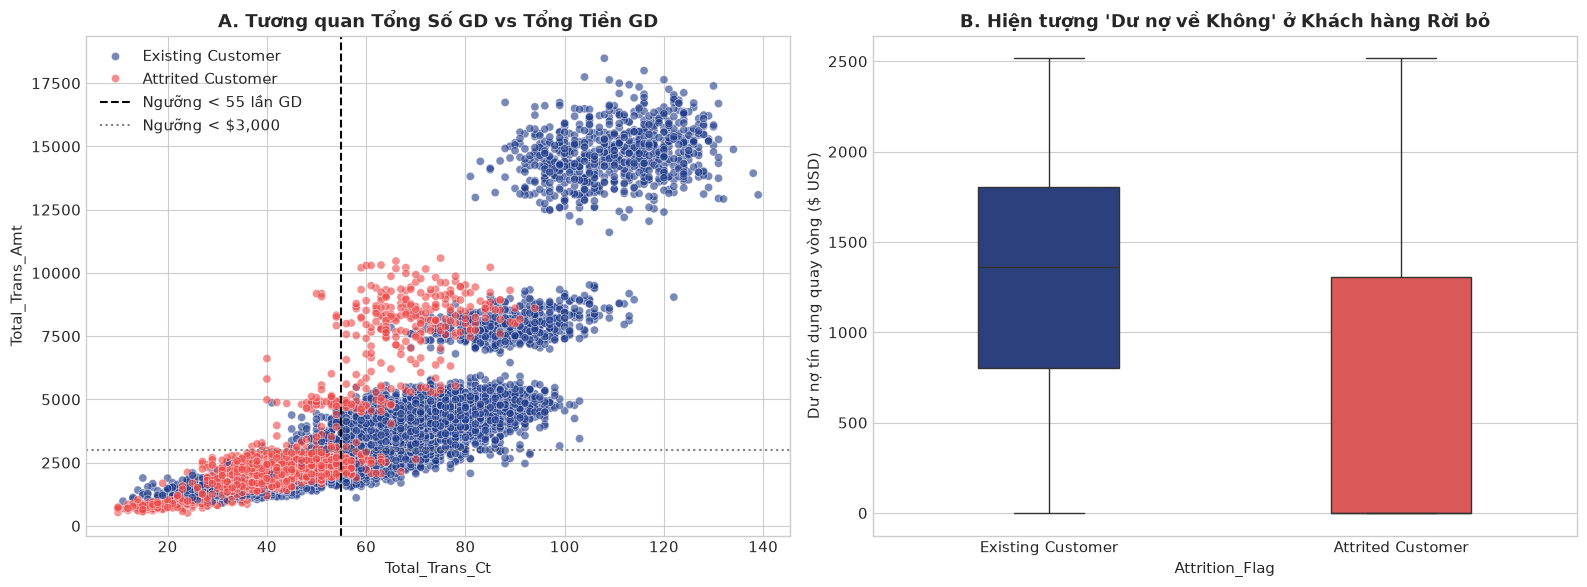

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Scatterplot Giao dịch
sns.scatterplot(
    data=df, x='Total_Trans_Ct', y='Total_Trans_Amt', hue='Attrition_Flag',
    palette=PALETTE, alpha=0.6, s=35, ax=axes[0]
)
axes[0].set_title("A. Tương quan Tổng Số GD vs Tổng Tiền GD")
axes[0].axvline(55, color='black', linestyle='--', label='Ngưỡng < 55 lần GD')
axes[0].axhline(3000, color='grey', linestyle=':', label='Ngưỡng < $3,000')
axes[0].legend(loc='upper left')

# Dư nợ quay vòng Boxplot
sns.boxplot(data=df, x='Attrition_Flag', y='Total_Revolving_Bal', palette=PALETTE, ax=axes[1], width=0.4)
axes[1].set_title("B. Hiện tượng 'Dư nợ về Không' ở Khách hàng Rời bỏ")
axes[1].set_ylabel("Dư nợ tín dụng quay vòng ($ USD)")

plt.tight_layout()
plt.show()


### 5.4. Phân tích Tương tác CSKH & Ma trận Tương quan Pearson

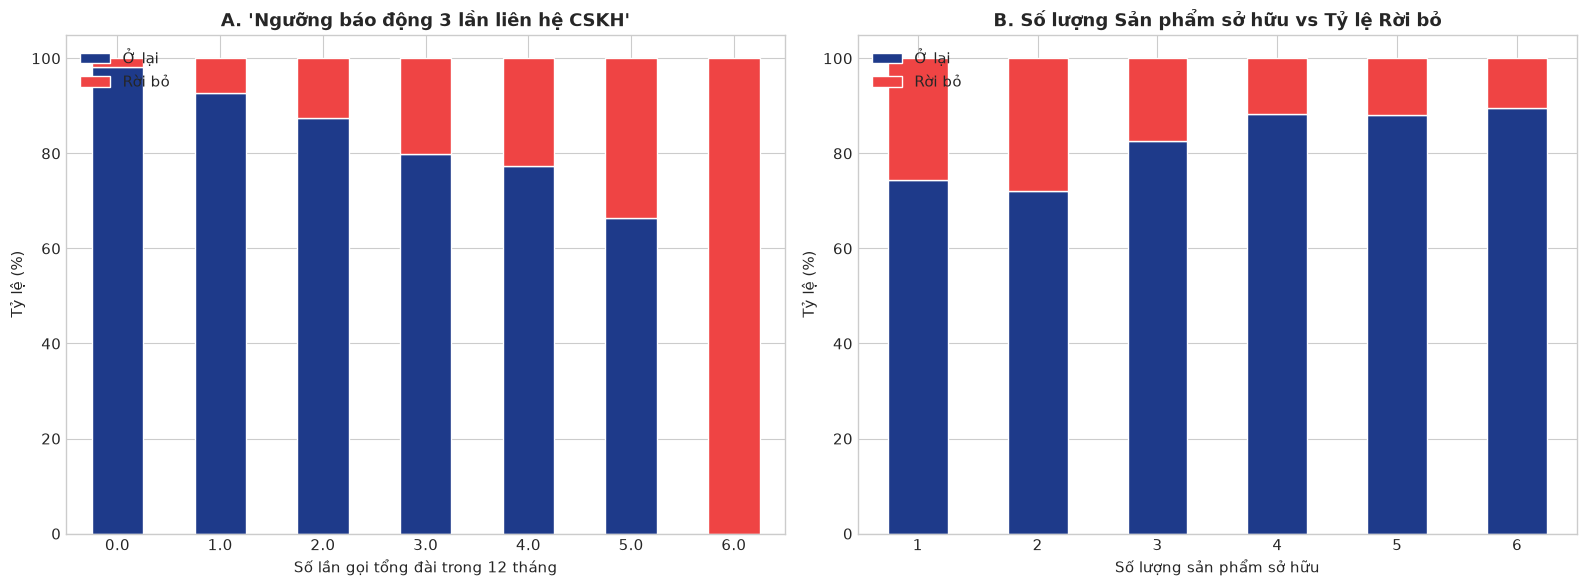

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Contacts count
contact_ct = pd.crosstab(df['Contacts_Count_12_mon'], df['Attrition_Flag'], normalize='index') * 100
contact_ct[['Existing Customer', 'Attrited Customer']].plot(
    kind='bar', stacked=True, color=[COLOR_EXISTING, COLOR_ATTRITED], ax=axes[0], edgecolor='white'
)
axes[0].set_title("A. 'Ngưỡng báo động 3 lần liên hệ CSKH'")
axes[0].set_xlabel("Số lần gọi tổng đài trong 12 tháng")
axes[0].set_ylabel("Tỷ lệ (%)")
axes[0].tick_params(axis='x', rotation=0)
axes[0].legend(['Ở lại', 'Rời bỏ'], loc='upper left')

# Relationship count
rel_ct = pd.crosstab(df['Total_Relationship_Count'], df['Attrition_Flag'], normalize='index') * 100
rel_ct[['Existing Customer', 'Attrited Customer']].plot(
    kind='bar', stacked=True, color=[COLOR_EXISTING, COLOR_ATTRITED], ax=axes[1], edgecolor='white'
)
axes[1].set_title("B. Số lượng Sản phẩm sở hữu vs Tỷ lệ Rời bỏ")
axes[1].set_xlabel("Số lượng sản phẩm sở hữu")
axes[1].set_ylabel("Tỷ lệ (%)")
axes[1].tick_params(axis='x', rotation=0)
axes[1].legend(['Ở lại', 'Rời bỏ'], loc='upper left')

plt.tight_layout()
plt.show()


## 🔍 6. Khai phá Dữ liệu (Data Mining) - Phân cụm Khách hàng K-Means
Sử dụng phương pháp học không giám sát (Unsupervised Learning) để tìm các phân khúc hành vi tự nhiên của khách hàng.
* Chuẩn hóa đặc trưng bằng `StandardScaler`.
* Xác định số cụm tối ưu $k$ qua **Elbow Method** (Điểm uốn) và **Silhouette Score**.
* Chiếu dữ liệu đa chiều lên không gian 2D bằng **PCA** (Principal Component Analysis).


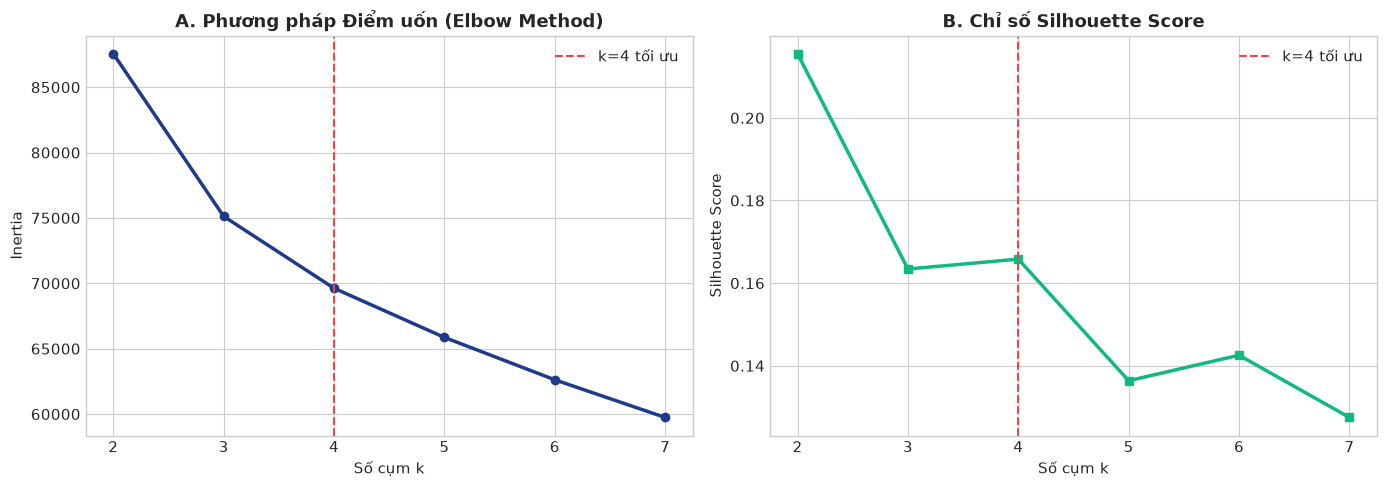

In [9]:
clustering_cols = [
    'Customer_Age', 'Credit_Limit', 'Total_Revolving_Bal', 'Avg_Utilization_Ratio',
    'Total_Trans_Amt', 'Total_Trans_Ct', 'Total_Ct_Chng_Q4_Q1', 'Contacts_Count_12_mon',
    'Months_Inactive_12_mon', 'Total_Relationship_Count'
]

scaler_cluster = StandardScaler()
X_cluster_scaled = scaler_cluster.fit_transform(df[clustering_cols])

# Đánh giá k từ 2 đến 8
k_range = range(2, 8)
inertias, sil_scores = [], []
for k in k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_cluster_scaled)
    inertias.append(km.inertia_)
    sil_scores.append(silhouette_score(X_cluster_scaled, km.labels_))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(k_range, inertias, marker='o', color='#1E3A8A', linewidth=2.5)
axes[0].set_title("A. Phương pháp Điểm uốn (Elbow Method)")
axes[0].set_xlabel("Số cụm k")
axes[0].set_ylabel("Inertia")
axes[0].axvline(4, color='#EF4444', linestyle='--', label='k=4 tối ưu')
axes[0].legend()

axes[1].plot(k_range, sil_scores, marker='s', color='#10B981', linewidth=2.5)
axes[1].set_title("B. Chỉ số Silhouette Score")
axes[1].set_xlabel("Số cụm k")
axes[1].set_ylabel("Silhouette Score")
axes[1].axvline(4, color='#EF4444', linestyle='--', label='k=4 tối ưu')
axes[1].legend()
plt.tight_layout()
plt.show()


In [10]:
# Huấn luyện K-Means với k=4 & Chiếu PCA
kmeans_model = KMeans(n_clusters=4, random_state=42, n_init=10)
df['Cluster'] = kmeans_model.fit_predict(X_cluster_scaled)

pca = PCA(n_components=2, random_state=42)
pca_res = pca.fit_transform(X_cluster_scaled)
df['PCA1'] = pca_res[:, 0]
df['PCA2'] = pca_res[:, 1]

cluster_labels = {
    0: 'Cụm 0: Tiêu dùng phổ thông ổn định',
    1: 'Cụm 1: Ngủ đông & Rủi ro rời bỏ cao',
    2: 'Cụm 2: Khách hàng Cao cấp / Chi tiêu lớn',
    3: 'Cụm 3: Tín dụng quay vòng / Vay tiêu dùng'
}
df['Cluster_Name'] = df['Cluster'].map(cluster_labels)

# Hồ sơ đặc trưng trung bình của 4 cụm
print("=== HỒ SƠ ĐẶC TRƯNG 4 PHÂN CỤM HÀNH VI KHÁCH HÀNG ===")
cluster_profile = df.groupby('Cluster').agg({
    'Total_Trans_Ct': 'mean',
    'Total_Trans_Amt': 'mean',
    'Total_Revolving_Bal': 'mean',
    'Avg_Utilization_Ratio': 'mean',
    'Credit_Limit': 'mean',
    'Contacts_Count_12_mon': 'mean',
    'Months_Inactive_12_mon': 'mean',
    'Churn_Binary': ['count', 'mean']
})
cluster_profile


=== HỒ SƠ ĐẶC TRƯNG 4 PHÂN CỤM HÀNH VI KHÁCH HÀNG ===


Total_Trans_Ct Total_Trans_Amt Total_Revolving_Bal  \
                  mean            mean                mean   
Cluster                                                      
0            62.919972     3531.727381         1667.374258   
1            54.623436     2989.424915         1348.383675   
2            58.655611     3372.765829          246.657286   
3           102.943734    12280.445865         1405.840580   

        Avg_Utilization_Ratio  Credit_Limit Contacts_Count_12_mon  \
                         mean          mean                  mean   
Cluster                                                             
0                    0.545627   3559.810544              2.363097   
1                    0.079853  21664.792947              2.560865   
2                    0.049346   5610.510184              2.641541   
3                    0.169251  14996.891731              2.157715   

        Months_Inactive_12_mon Churn_Binary            
                          mean        count      mean  
Cluster                                                
0                     2.308953         4211  0.080978  
1                     2.289534         1758  0.127986  
2                     2.471692         2985  0.341709  
3                     2.202899         1173  0.034953

## 🤖 7. Khai phá Dữ liệu: Mô hình Hóa Dự Báo Rời Bỏ (Supervised Learning)
Xây dựng và so sánh 4 thuật toán phân loại:
1. **Logistic Regression (Baseline)** — Giải thích xác suất tuyến tính.
2. **Decision Tree Classifier** — Cây quyết định phi tuyến tính.
3. **Random Forest Classifier** — Mô hình quần thể đóng bao (Bagging Ensemble).
4. **XGBoost Classifier** — Thuật toán Gradient Boosting tân tiến, tối ưu hóa ranh giới quyết định.


In [11]:
# Chuẩn bị ma trận đặc trưng
model_features = [
    'Customer_Age', 'Gender', 'Dependent_count', 'Education_Level', 'Marital_Status',
    'Income_Category', 'Card_Category', 'Months_on_book', 'Total_Relationship_Count',
    'Months_Inactive_12_mon', 'Contacts_Count_12_mon', 'Credit_Limit', 'Total_Revolving_Bal',
    'Avg_Open_To_Buy', 'Total_Amt_Chng_Q4_Q1', 'Total_Trans_Amt', 'Total_Trans_Ct',
    'Total_Ct_Chng_Q4_Q1', 'Avg_Utilization_Ratio', 'Avg_Trans_Value', 'Revolving_Ratio',
    'Contact_Intensity'
]

X = pd.get_dummies(df[model_features], drop_first=True)
y = df['Churn_Binary'].values

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Khởi tạo mô hình
models = {
    'Logistic Regression': LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42),
    'Decision Tree': DecisionTreeClassifier(max_depth=6, class_weight='balanced', random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=200, max_depth=12, class_weight='balanced', random_state=42, n_jobs=-1),
    'XGBoost Classifier': XGBClassifier(n_estimators=200, max_depth=5, learning_rate=0.08, scale_pos_weight=5.22, random_state=42, eval_metric='logloss')
}

eval_results = {}
fpr_dict, tpr_dict, auc_dict = {}, {}, {}

for name, clf in models.items():
    if name == 'Logistic Regression':
        clf.fit(X_train_scaled, y_train)
        y_pred = clf.predict(X_test_scaled)
        y_prob = clf.predict_proba(X_test_scaled)[:, 1]
    else:
        clf.fit(X_train, y_train)
        y_pred = clf.predict(X_test)
        y_prob = clf.predict_proba(X_test)[:, 1]
    
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred)
    rec = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    auc = roc_auc_score(y_test, y_prob)
    
    eval_results[name] = {'Accuracy': acc, 'Precision': prec, 'Recall': rec, 'F1-Score': f1, 'ROC-AUC': auc}
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    fpr_dict[name], tpr_dict[name], auc_dict[name] = fpr, tpr, auc

pd.DataFrame(eval_results).T


,Accuracy,Precision,Recall,F1-Score,ROC-AUC
Logistic Regression,0.869694,0.563410,0.833846,0.672457,0.934797
Decision Tree,0.910661,0.665899,0.889231,0.761528,0.945804
Random Forest,0.947680,0.815562,0.870769,0.842262,0.983800
XGBoost Classifier,0.965449,0.876106,0.913846,0.894578,0.992996


## 📈 8. Đánh giá Hiệu năng & Bóc tách Tầm quan trọng Đặc trưng

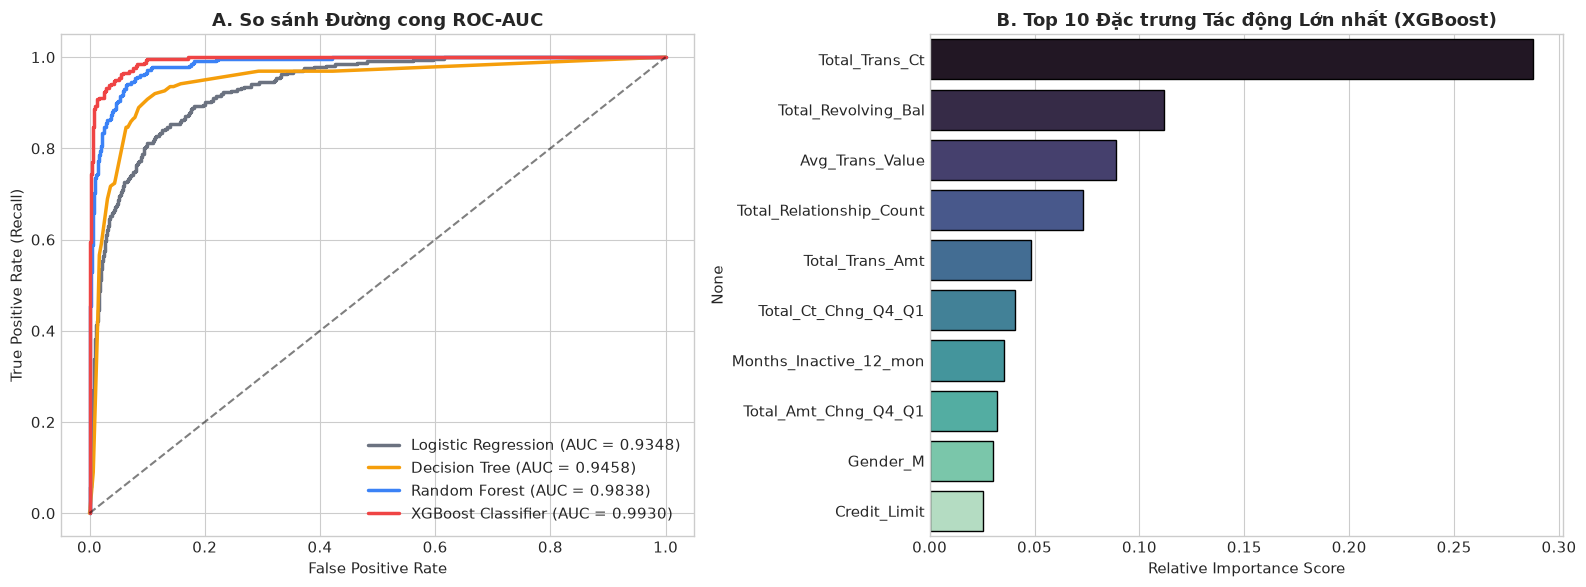

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Đường cong ROC
colors = {'Logistic Regression': '#6B7280', 'Decision Tree': '#F59E0B', 'Random Forest': '#3B82F6', 'XGBoost Classifier': '#EF4444'}
for name in models.keys():
    axes[0].plot(fpr_dict[name], tpr_dict[name], label=f"{name} (AUC = {auc_dict[name]:.4f})", color=colors[name], linewidth=2.5)
axes[0].plot([0, 1], [0, 1], 'k--', alpha=0.5)
axes[0].set_title("A. So sánh Đường cong ROC-AUC")
axes[0].set_xlabel("False Positive Rate")
axes[0].set_ylabel("True Positive Rate (Recall)")
axes[0].legend(loc='lower right')

# Feature Importance của XGBoost
xgb = models['XGBoost Classifier']
feat_imp = pd.Series(xgb.feature_importances_, index=X.columns).sort_values(ascending=False).head(10)
sns.barplot(x=feat_imp.values, y=feat_imp.index, palette='mako', ax=axes[1], edgecolor='black')
axes[1].set_title("B. Top 10 Đặc trưng Tác động Lớn nhất (XGBoost)")
axes[1].set_xlabel("Relative Importance Score")

plt.tight_layout()
plt.show()


## 💰 9. Tối ưu hóa Ngưỡng Xác suất & Bài toán Kinh tế Giữ chân
* Giá trị khách hàng ở lại: $\$500$
* Chi phí can thiệp / quà tặng giữ chân: $\$50$
* Tổn thất nếu khách rời bỏ mà không can thiệp: $-\$500$


🎯 Ngưỡng cắt xác suất tối ưu: 0.06
💵 Lợi nhuận ròng tối đa đạt được trên tập Test: $136,600 USD


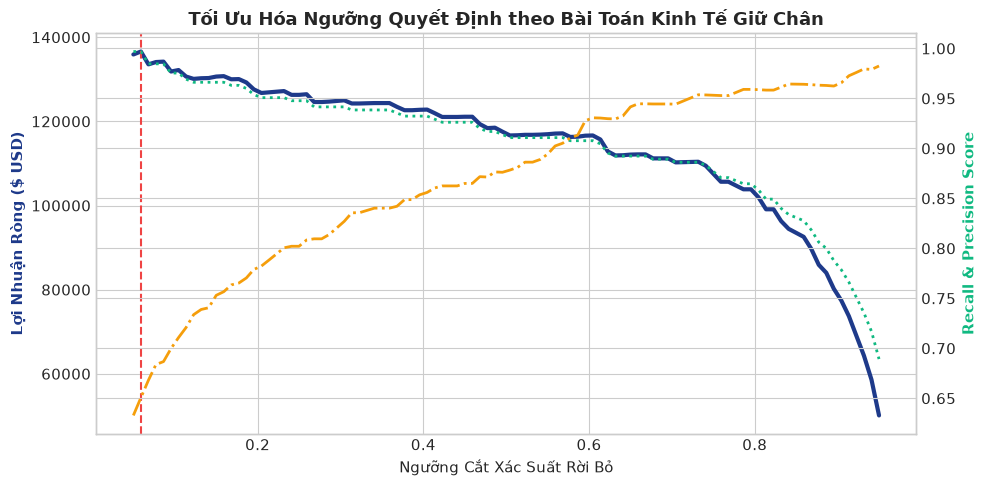

In [13]:
xgb_prob = models['XGBoost Classifier'].predict_proba(X_test)[:, 1]
thresholds = np.linspace(0.05, 0.95, 100)
profits, recalls, precisions = [], [], []

for t in thresholds:
    pred = (xgb_prob >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    profit = tp * 450 - fp * 50 - fn * 500
    profits.append(profit)
    recalls.append(recall_score(y_test, pred))
    precisions.append(precision_score(y_test, pred, zero_division=0))

opt_idx = np.argmax(profits)
print(f"🎯 Ngưỡng cắt xác suất tối ưu: {thresholds[opt_idx]:.2f}")
print(f"💵 Lợi nhuận ròng tối đa đạt được trên tập Test: ${profits[opt_idx]:,.0f} USD")

fig, ax1 = plt.subplots(figsize=(10, 5))
ax1.plot(thresholds, profits, color='#1E3A8A', linewidth=3, label='Lợi nhuận ròng ($ USD)')
ax1.axvline(thresholds[opt_idx], color='#EF4444', linestyle='--', label=f'Ngưỡng Tối Ưu = {thresholds[opt_idx]:.2f}')
ax1.set_xlabel('Ngưỡng Cắt Xác Suất Rời Bỏ')
ax1.set_ylabel('Lợi Nhuận Ròng ($ USD)', color='#1E3A8A', fontweight='bold')

ax2 = ax1.twinx()
ax2.plot(thresholds, recalls, color='#10B981', linestyle=':', linewidth=2, label='Recall')
ax2.plot(thresholds, precisions, color='#F59E0B', linestyle='-.', linewidth=2, label='Precision')
ax2.set_ylabel('Recall & Precision Score', color='#10B981', fontweight='bold')

plt.title("Tối Ưu Hóa Ngưỡng Quyết Định theo Bài Toán Kinh Tế Giữ Chân")
plt.tight_layout()
plt.show()


## 🎯 10. Tổng kết & Khung Khuyến nghị Quản trị Giữ chân Khách hàng

### 📌 3 Chân dung Khách hàng Rời bỏ Điển hình (Customer Personas):
1. **Chân dung 1: Khách hàng 'Ngủ đông' & Rút lui lặng lẽ (The Silent Defector - 55%):**
   * Dư nợ quay vòng $= 0$ USD, giao dịch $< 45$ lần/năm, ngủ đông $\ge 3$ tháng.
   * *Giải pháp:* Tự động kích hoạt Voucher hoàn tiền theo tuần và chiến dịch Gamification trên Mobile App.
2. **Chân dung 2: Khách hàng Bức xúc Dịch vụ & Khiếu nại (The Frustrated Complainer - 25%):**
   * Gọi CSKH $\ge 3$ lần, chỉ dùng $1-2$ sản phẩm.
   * *Giải pháp:* Thiết lập quy trình First-Contact Resolution (FCR) và đường dây nóng hỗ trợ ưu tiên (Retention Taskforce).
3. **Chân dung 3: Khách hàng VIP Dịch chuyển Nhà cung cấp (The VIP Switcher - 20%):**
   * Thu nhập cao ($\ge \$120	ext{K}$), thẻ Gold/Platinum, chi tiêu Q4 giảm đột ngột $> 40\%$.
   * *Giải pháp:* Nâng cấp đặc quyền phòng chờ sân bay, nhân đôi dặm bay thưởng và hạn mức tín dụng linh hoạt.

---
### 🏛️ KHUNG CHIẾN LƯỢC GIỮ CHÂN 4 TẦNG (4-TIER RETENTION FRAMEWORK):
1. **Tầng 1: Hệ thống Cảnh báo Sớm (Early Warning System - EWS):** Giám sát thời gian thực các Trigger Point (Cảnh báo Vàng khi ngủ đông 2 tháng, Cảnh báo Đỏ khi liên hệ CSKH lần 3).
2. **Tầng 2: CSKH Chủ động (Proactive Retention Care):** Giải quyết dứt điểm khiếu nại trong 24 giờ & chính sách miễn giảm phí linh hoạt.
3. **Tầng 3: Chương trình Khách hàng Thân thiết (Gamified Loyalty):** Tích điểm theo tần suất quẹt thẻ thay vì chỉ tính theo tổng tiền.
4. **Tầng 4: Bán chéo Hệ sinh thái (Cross-selling):** Gắn kết khách hàng với $\ge 4$ sản phẩm tài chính để nâng cao rào cản chuyển đổi (*Switching Barriers*).

---
**Báo cáo được thực hiện bởi:** Đỗ Văn Đạt — Học viện Ngân hàng  
**Năm học:** 2025 - 2026
